<a href="https://colab.research.google.com/github/jysim128/K-pop-Vocal-Timbre/blob/main/section_count.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Count Trap Sections


In [ ]:
import librosa
import pandas as pd
import os
import matplotlib.pyplot as plt
import glob
from google.colab import drive
import re
drive.mount('/content/drive')

TRAP_LABEL_DIR = "/content/drive/MyDrive/1. separated audio/trap_labels"
FORMAL_LABEL_DIR = "/content/drive/MyDrive/1. separated audio/unified_labels"
AUDIO_FILES_DIR = "/content/drive/MyDrive/1. separated audio/audio"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
def merge_formal_trap(formal_dir, trap_dir, verbose=True):
    """formal 라벨(start, end, label) 옆에 trap 라벨의 label을 trap_label 열로 붙여 반환."""

    def load(directory):
        paths = sorted(glob.glob(os.path.join(directory, "*.txt")))
        if not paths:
            raise FileNotFoundError(f"No .txt label files in {directory}")
        dfs = []
        for path in paths:
            df = pd.read_csv(path, sep=None, engine="python",
                             names=["start", "end", "label"], header=None)
            stem = os.path.splitext(os.path.basename(path))[0]
            key = re.sub(r"_(FORM|TRAP)[A-Z]*$", "", stem, flags=re.IGNORECASE)
            dfs.append(df.assign(key=key))
        df = pd.concat(dfs, ignore_index=True)
        df["idx"] = df.groupby("key").cumcount()
        return df

    formal = load(formal_dir)
    trap   = load(trap_dir).rename(columns={"label": "trap_label"})

    merged = formal[["key", "idx", "start", "end", "label"]].merge(
        trap[["key", "idx", "trap_label"]],
        on=["key", "idx"], how="left"
    ).drop(columns="idx").rename(columns={"key": "song"})

    if verbose:
        n_empty = merged["trap_label"].isna().sum()
        print(f"총 {len(merged)}행, trap_label 비어 있는 행: {n_empty}")
        if n_empty:
            print("비어 있는 행이 있는 곡:",
                  merged.loc[merged["trap_label"].isna(), "song"].unique().tolist())

    return merged

In [ ]:
merged_df = merge_formal_trap(FORMAL_LABEL_DIR, TRAP_LABEL_DIR)
merged_df.head()

총 1201행, trap_label 비어 있는 행: 0


,song,start,end,label,trap_label
0,01_BLACKPINK_ASIFITSYOURLAST,0.000000,15.680000,I,I
1,01_BLACKPINK_ASIFITSYOURLAST,15.701333,31.146667,V1a,V1a
2,01_BLACKPINK_ASIFITSYOURLAST,31.168000,46.528000,V1b,V1b
3,01_BLACKPINK_ASIFITSYOURLAST,46.570667,62.933333,P1,P1
4,01_BLACKPINK_ASIFITSYOURLAST,62.954667,79.296000,C1,C1


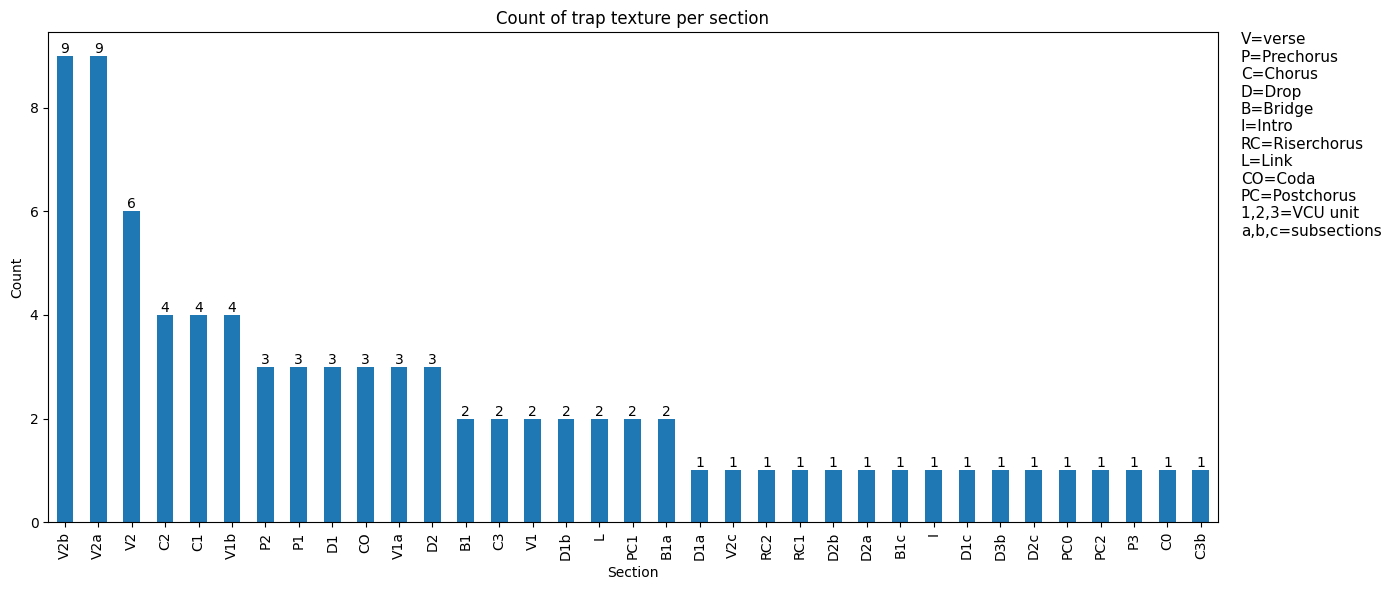

In [ ]:
# Visualization
import matplotlib.pyplot as plt

trap_rows = merged_df["trap_label"].str.contains("trap")
counts = merged_df.loc[trap_rows, "label"].value_counts()
ax= counts.plot(kind="bar", figsize=(14,6))
ax.bar_label(ax.containers[0])

plt.title("Count of trap texture per section")
plt.xlabel("Section")
plt.ylabel("Count")

legend_text = "\n".join(["V=verse", "P=Prechorus", "C=Chorus", "D=Drop", "B=Bridge", "I=Intro", "RC=Riserchorus", "L=Link","CO=Coda", "PC=Postchorus", "1,2,3=VCU unit", "a,b,c=subsections"])
ax.text(1.02, 1, legend_text, transform=ax.transAxes, va="top", fontsize=11)

plt.tight_layout()
plt.show()